# OpenAI-Whisper local ASR

In [1]:
import matplotlib.pyplot as plt
import IPython.display as ipd
import numpy as np

from transformers import WhisperProcessor, WhisperForConditionalGeneration
from datasets import load_dataset

import librosa
import noisereduce as nr

## Load model

In [2]:
# load model and processor
processor = WhisperProcessor.from_pretrained("openai/whisper-tiny") # tiny, base, small, medium, large
model = WhisperForConditionalGeneration.from_pretrained("openai/whisper-tiny")
model.config.forced_decoder_ids = None


## Preprocessing function

In [3]:
def denoise_audio(audio, sr):
    return nr.reduce_noise(y=audio, sr=sr)

In [4]:
def normalize_audio(audio):
    return librosa.util.normalize(audio)

In [19]:
# Removes leading and trailing silence
def trim_silence(audio, top_db=30):
    trimmed_audio, _ = librosa.effects.trim(audio, top_db=top_db)
    return trimmed_audio

In [20]:
# Clipping amplitude to avoid spikes
def limit_volume(audio, threshold=0.8):
    return np.clip(audio, -threshold, threshold)

In [5]:
def chunk_audio(audio, sr, chunk_length_sec=30):
    chunk_length = sr * chunk_length_sec
    return [audio[i:i+chunk_length] for i in range(0, len(audio), chunk_length)]

In [32]:
def preprocess_audio(audio, sr):
    audio = trim_silence(audio)           # Silence trimming
    audio = denoise_audio(audio, sr)      # Noise reduction
    audio = limit_volume(audio)           # Volume adjustment (clipping)
    audio = normalize_audio(audio)        # Normalization
    chunks = chunk_audio(audio, sr)       # Chunking
    return chunks

## Transcribe and translate function

In [7]:
# given an audio file, return the predicted transcription
def transcribe(audio, lang="it"):
    input_features = processor(audio, sampling_rate=16000, return_tensors="pt").input_features

    # generate token ids with language and task
    predicted_ids = model.generate(
        input_features,
        language=lang,
        task="transcribe"
    )

    transcription = processor.batch_decode(predicted_ids, skip_special_tokens=True)[0]
    return transcription

In [8]:
# given an audio file, return the predicted english translation
def translate(audio, lang="it"):
    input_features = processor(audio, sampling_rate=16000, return_tensors="pt").input_features

    # generate token ids with language and task
    predicted_ids = model.generate(
        input_features,
        language=lang,
        task="translate"
    )

    translation = processor.batch_decode(predicted_ids, skip_special_tokens=True)[0]
    return translation

## Test inference

### Load audio

In [9]:
# audio_file = "./test_files/eng.wav"
# audio_file = "./test_files/rab-m3-n4.wav"
# audio_file = "./test_files/sor-m3-l4.wav"
audio_file = "./test_files/pau-m3-d2.wav"
audio, sr = librosa.load(audio_file, sr=16000)

# preview the audio
ipd.Audio(audio, rate=sr)

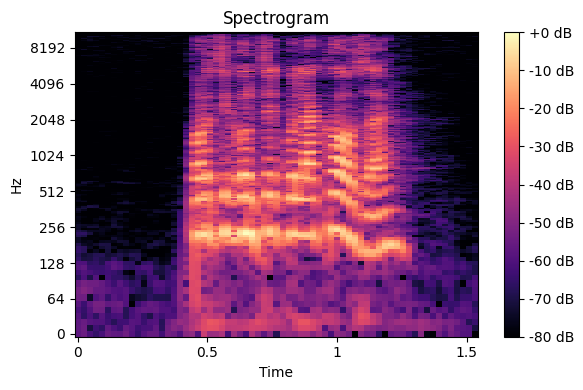

In [10]:
# plot the audio spectrogram
plt.figure(figsize=(6, 4))
librosa.display.specshow(librosa.amplitude_to_db(np.abs(librosa.stft(audio)), ref=np.max), y_axis='log', x_axis='time')
plt.title('Spectrogram')
plt.colorbar(format='%+2.0f dB')
plt.tight_layout()
plt.show()

### simple inference

In [11]:
transcription = transcribe(audio, lang="it")
print("+", transcription, "+\n")

translation = translate(audio, lang="it")
print("+", translation, "+")

The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


+  Porti con te quella cosa? +

+  I'll tell you something. +


### with preprocessing

#### transcription

In [66]:
transcription = transcribe(audio, lang="it")
print("Base audio: ", transcription)

denoised_audio = denoise_audio(audio, sr)
transcription = transcribe(denoised_audio, lang="it")
print("Denoised audio: ", transcription)

normalized_audio = normalize_audio(audio)
transcription = transcribe(normalized_audio, lang="it")
print("Normalized audio: ", transcription)

trimmed_audio = trim_silence(audio)
transcription = transcribe(trimmed_audio, lang="it")
print("Trimmed audio: ", transcription)

limited_vol_audio = limit_volume(audio, threshold=0.01)
transcription = transcribe(limited_vol_audio, lang="it")
print("Limited volume audio: ", transcription)

processed_chunks = preprocess_audio(audio, sr)
for i, chunk in enumerate(processed_chunks):
    transcription = transcribe(chunk, lang="it")
    print(f"Processed chunk ({i+1}): ", transcription)

Base audio:   Porti con te quella cosa?
Denoised audio:   Porti con te quella cosa.
Normalized audio:   porti con te quella cosa
Trimmed audio:   Parti con te quella cosa.
Limited volume audio:   Porti conti con la cosa.
Processed chunk (1):   Porti con tecola cosa.


#### visualization

In [62]:
denoised_audio = denoise_audio(audio, sr)
normalized_audio = normalize_audio(audio)
trimmed_audio = trim_silence(audio)
limited_vol_audio = limit_volume(audio, threshold=0.01)
processed_chunks = preprocess_audio(audio, sr)

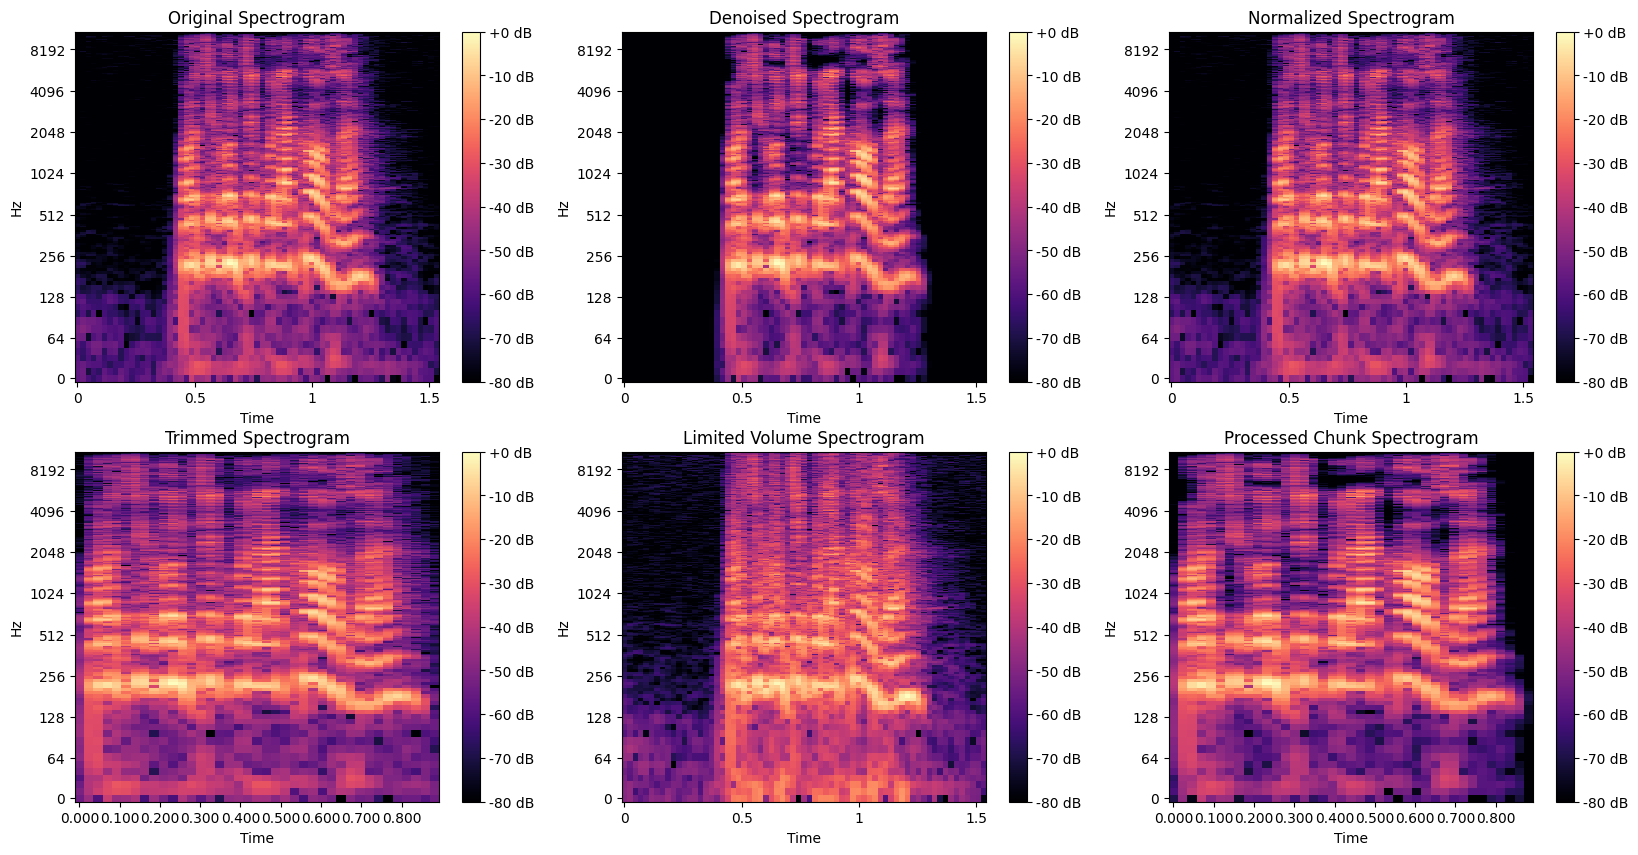

In [63]:
# plot pre and post processing spectrograms
plt.figure(figsize=(20, 10))
plt.subplot(2, 3, 1)
librosa.display.specshow(librosa.amplitude_to_db(np.abs(librosa.stft(audio)), ref=np.max), y_axis='log', x_axis='time')
plt.title('Original Spectrogram')
plt.colorbar(format='%+2.0f dB')
plt.subplot(2, 3, 2)
librosa.display.specshow(librosa.amplitude_to_db(np.abs(librosa.stft(denoised_audio)), ref=np.max), y_axis='log', x_axis='time')
plt.title('Denoised Spectrogram')
plt.colorbar(format='%+2.0f dB')
plt.subplot(2, 3, 3)
librosa.display.specshow(librosa.amplitude_to_db(np.abs(librosa.stft(normalized_audio)), ref=np.max), y_axis='log', x_axis='time')
plt.title('Normalized Spectrogram')
plt.colorbar(format='%+2.0f dB')
plt.subplot(2, 3, 4)
librosa.display.specshow(librosa.amplitude_to_db(np.abs(librosa.stft(trimmed_audio)), ref=np.max), y_axis='log', x_axis='time')
plt.title('Trimmed Spectrogram')
plt.colorbar(format='%+2.0f dB')
plt.subplot(2, 3, 5)
librosa.display.specshow(librosa.amplitude_to_db(np.abs(librosa.stft(limited_vol_audio)), ref=np.max), y_axis='log', x_axis='time')
plt.title('Limited Volume Spectrogram')
plt.colorbar(format='%+2.0f dB')
plt.subplot(2, 3, 6)
librosa.display.specshow(librosa.amplitude_to_db(np.abs(librosa.stft(processed_chunks[0])), ref=np.max), y_axis='log', x_axis='time')
plt.title('Processed Chunk Spectrogram')
plt.colorbar(format='%+2.0f dB')
plt.show()